# Lab 3: Decision Trees and Random Forests

Two classification problems:

1. **Banknote authentication:** is a banknote genuine or forged, from four image-derived features?
2. **Hiring decisions:** predict whether a candidate was hired from their CV details (a tiny 13-row dataset).

## 1. Banknote authentication

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
dataset = pd.read_csv("bill_authentication.csv")

In [3]:
dataset.shape

(1372, 5)

In [4]:
dataset.head(20)

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


`Class` is the target (0 = genuine, 1 = forged). The other four columns are features.

In [5]:
x = dataset.drop('Class', axis = 1)
y = dataset['Class']

In [6]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state = 42
)

In [7]:
print("Training examples:", len(x_train))
print("Testing examples:", len(x_test))

Training examples: 1097
Testing examples: 275


### Decision tree

In [8]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier(random_state = 42)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)

In [9]:
print("First 10 predictions: ", y_pred[:10])
print("First 10 true labels:", y_test.iloc[:10].to_list())

First 10 predictions:  [0 0 0 0 0 0 0 0 0 0]
First 10 true labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [10]:
from sklearn.metrics import  confusion_matrix, classification_report, accuracy_score
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[148   0]
 [  5 122]]
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       148
           1       1.00      0.96      0.98       127

    accuracy                           0.98       275
   macro avg       0.98      0.98      0.98       275
weighted avg       0.98      0.98      0.98       275



### Random forest, for comparison

A random forest trains many trees on random subsets of the data and features, then takes a majority vote.

In [11]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(x_train, y_train)
forest_pred = forest.predict(x_test)

print(confusion_matrix(y_test, forest_pred))
print(f"Decision tree accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Random forest accuracy: {accuracy_score(y_test, forest_pred):.3f}")

[[148   0]
 [  2 125]]
Decision tree accuracy: 0.982
Random forest accuracy: 0.993


### Which features matter most?

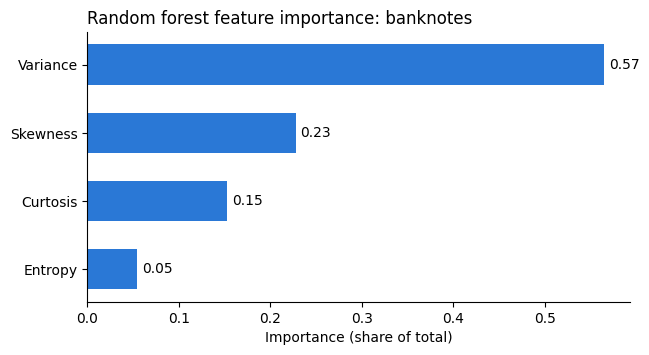

In [12]:
importance = pd.Series(forest.feature_importances_, index=x.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(importance.index, importance.values, color='#2a78d6', height=0.6)
for i, v in enumerate(importance.values):
    ax.text(v + 0.005, i, f'{v:.2f}', va='center')
ax.set_xlabel('Importance (share of total)')
ax.set_title('Random forest feature importance: banknotes', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 2. Hiring decisions

In [13]:
import pandas as pd
import numpy as np
from sklearn import tree

In [14]:
df = pd.read_csv("PastHires.csv")

In [15]:
df.columns.tolist()

['Years Experience',
 'Employed?',
 'Previous employers',
 'Level of Education',
 'Top-tier school',
 'Interned',
 'Hired']

In [16]:
df.shape

(13, 7)

In [17]:
df.head()

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,Y,4,BS,N,N,Y
1,0,N,0,BS,Y,Y,Y
2,7,N,6,BS,N,N,N
3,2,Y,1,MS,Y,N,Y
4,20,N,2,PhD,Y,N,N


Convert Y/N columns to 1/0 and education level to an ordered number (BS < MS < PhD).

In [18]:
yes_no_map = {"Y":1, "N":0}

In [19]:
education_map = {"BS":0, "MS":1, "PhD":2}

In [20]:
for column in ["Hired", "Employed?", "Top-tier school", "Interned"]:
    df[column] = df[column].map(yes_no_map)

df["Level of Education"] = df["Level of Education"].map(education_map)

In [21]:
df.head(13)

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,1,4,0,0,0,1
1,0,0,0,0,1,1,1
2,7,0,6,0,0,0,0
3,2,1,1,1,1,0,1
4,20,0,2,2,1,0,0
5,0,0,0,2,1,1,1
6,5,1,2,1,0,1,1
7,3,0,1,0,0,1,1
8,15,1,5,0,0,0,1
9,0,0,0,0,0,0,0


In [22]:
df.isnull().sum()

Years Experience      0
Employed?             0
Previous employers    0
Level of Education    0
Top-tier school       0
Interned              0
Hired                 0
dtype: int64

In [23]:
features = [column for column in df.columns if column != "Hired"]
print("features:", features)

y = df["Hired"]
x = df[features]

features: ['Years Experience', 'Employed?', 'Previous employers', 'Level of Education', 'Top-tier school', 'Interned']


In [24]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state = 42
)

In [25]:
print("Training examples:", len(x_train))
print("Testing examples:", len(x_test))

Training examples: 10
Testing examples: 3


In [26]:
from sklearn.tree import DecisionTreeClassifier

classifier = DecisionTreeClassifier(random_state = 42)
classifier.fit(x_train, y_train)

y_pred = classifier.predict(x_test)

In [27]:
print("Test set predictions:", y_pred)
print("Test set true labels: ", y_test.to_list())

Test set predictions: [1 1 1]
Test set true labels:  [1, 0, 1]


### Visualising the decision tree

Train on all 13 candidates so the tree shows the full set of hiring rules.

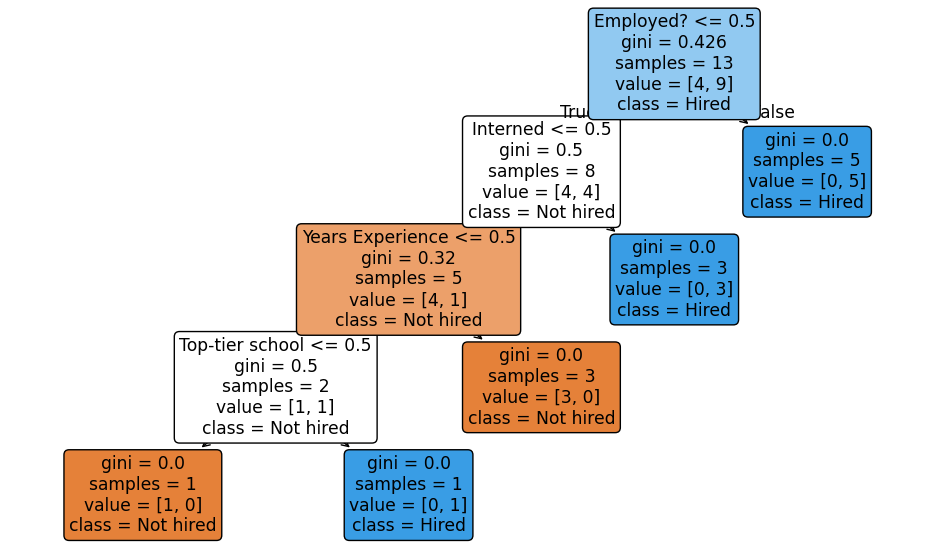

In [28]:
full_tree = DecisionTreeClassifier(random_state=42).fit(x, y)

fig, ax = plt.subplots(figsize=(12, 7))
tree.plot_tree(full_tree, feature_names=features, class_names=['Not hired', 'Hired'], filled=True, rounded=True, ax=ax)
plt.show()

### Evaluating fairly on a tiny dataset

With only 13 rows, a 3-row test set makes accuracy swing wildly from one split to the next. **Leave-one-out cross-validation** is more reliable: train on 12, test on the 1 left out, and repeat 13 times.

In [29]:
from sklearn.model_selection import LeaveOneOut, cross_val_score

loo = LeaveOneOut()
tree_scores = cross_val_score(DecisionTreeClassifier(random_state=42), x, y, cv=loo)
forest_scores = cross_val_score(RandomForestClassifier(n_estimators=10, random_state=42), x, y, cv=loo)

print(f"Decision tree: {tree_scores.mean():.2f} accuracy ({int(tree_scores.sum())}/13 correct)")
print(f"Random forest: {forest_scores.mean():.2f} accuracy ({int(forest_scores.sum())}/13 correct)")

Decision tree: 0.54 accuracy (7/13 correct)
Random forest: 0.69 accuracy (9/13 correct)


### Random forest predictions for new candidates

In [30]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(n_estimators=10, random_state=42)
clf = clf.fit(x_train, y_train)

print(clf.predict(x_test))

[1 1 1]


In [31]:
clf = RandomForestClassifier(n_estimators=10, random_state=42).fit(x, y)

candidates = pd.DataFrame([
    [10, 1, 4, 0, 0, 0],   # employed, 10 years' experience
    [10, 0, 4, 0, 0, 0],   # unemployed, 10 years' experience
], columns=features)

for (_, row), pred in zip(candidates.iterrows(), clf.predict(candidates)):
    status = 'employed' if row['Employed?'] else 'unemployed'
    print(f"{status}, {row['Years Experience']} years' experience -> {'Hired' if pred else 'Not hired'}")

employed, 10 years' experience -> Hired
unemployed, 10 years' experience -> Not hired


**Findings:** on the banknote data both models are highly accurate (about 98% or above), and the random forest edges out the single tree. Variance is the most important feature. The hiring dataset is too small to judge either model reliably, which is why leave-one-out cross-validation gives a fairer score than a single 3-row test set.